<a href="https://colab.research.google.com/github/statftn/Deep-Learning-Theory-and-Practice/blob/main/chapter08_image_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [ ]:
!pip install keras keras-hub --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 17.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [ ]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

## Image classification

### Introduction to ConvNets

In [ ]:
import keras
from keras import layers

inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(inputs)   # Conv2D: padding (특성맵 가장자리에 행, 열 추가) 기본값 valid (패딩 사용X)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation="softmax")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

In [ ]:
model.summary(line_length=80)
# Conv2D와 MaxPooling2D 층의 출력은 (height, width, channels) 크기의 3D tensor
# channels(depth): RGB이미지는 3개의 채널을 가진다. 출력 특성 맵의 경우 depth는 입력 데이터의 특성을 인코딩하는 필터
# 마지막 Conv2D 출력은 (3, 3, 256). 256개의 채널을 가진 3x3 크기의 특성 맵
# GlobalAveragePooling2D: (3, 3, 256) 크기 텐서에서 3x3 특성 맵마다 평균을 계산
# 마지막 층 출력 크기 10, 활성화함수 softmax -> 10개의 클래스 분류

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)          │ (None, 28, 28, 1)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d (Conv2D)                   │ (None, 26, 26, 64)       │           640 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)      │ (None, 13, 13, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                 │ (None, 11, 11, 128)      │        73,856 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)    │ (None, 5, 5, 128)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)                 │ (None, 3, 3, 256)        │       295,168 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ global_average_pooling2d          │ (None, 256)              │             0 │
│ (GlobalAveragePooling2D)          │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, 10)               │         2,570 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 372,234 (1.42 MB)

 Trainable params: 372,234 (1.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28, 28, 1))   # add one more dimension for depth
train_images = train_images.astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype("float32") / 255
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # sparse_categorical_crossentropy: 정수 레이블, 범주형 크로스엔트로피 손실 -> 10개의 클래스 분류
    metrics=["accuracy"],
)
model.fit(train_images, train_labels, epochs=5, batch_size=64)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9227 - loss: 0.2456
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9789 - loss: 0.0682
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9859 - loss: 0.0453
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9893 - loss: 0.0335
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9910 - loss: 0.0285


In [ ]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Test accuracy: {test_acc:.3f}")
# chapter2에서 fully connected network는 테스트 정확도 97.8%
# Convnet은 99.1%
# dense층은 입력 특성 공간에 있는 전역 패턴을 학습하지만, 합성곱 층은 지역 패턴을 학습
# Convnet은 패턴의 공간적 계층 구조를 학습 가능

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9910 - loss: 0.0268
Test accuracy: 0.991


#### The convolution operation

##### Understanding border effects and padding

##### Understanding convolution strides

#### The max-pooling operation

In [ ]:
# no max pooling
# max pooling (또는 average pooling) 하지 않을 경우 stride 조절하여 단점 보완 가능
# stride: 두 번의 연속적인 합성곱 윈도우 사이 거리 (기본값 1)
inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(inputs)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)   # not very good (22*22 -> one value)
outputs = layers.Dense(10, activation="softmax")(x)
model_no_max_pool = keras.Model(inputs=inputs, outputs=outputs)

In [ ]:
model_no_max_pool.summary(line_length=80)

# 세 번째 층의 3x3 윈도우는 초기 입력의 7x7 윈도우 영역에 대한 정보만 담고 있다
# (7x7 크기의 입력을 3x3 윈도우로 합성곱하면 5x5, 다시 한번 합성곱하면 3x3)
# 따라서 학습된 고수준 패턴이 초기 입력에 돤한 정보가 아주 적어 숫자 분류를 학습하기에 충분하지 않다

# 최종 특성 맵의 차원은 22x22. 22x22 특성 맵의 평균을 내면 많은 정보가 파괴

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)        │ (None, 28, 28, 1)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)                 │ (None, 26, 26, 64)       │           640 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)                 │ (None, 24, 24, 128)      │        73,856 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)                 │ (None, 22, 22, 256)      │       295,168 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ global_average_pooling2d_1        │ (None, 256)              │             0 │
│ (GlobalAveragePooling2D)          │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 10)               │         2,570 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 372,234 (1.42 MB)

 Trainable params: 372,234 (1.42 MB)

 Non-trainable params: 0 (0.00 B)

Some questions

In [ ]:
# Run model.summary () for the MNIST classification
from keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28, 28, 1))   # add one more dimension for depth
train_images = train_images.astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype("float32") / 255
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(train_images, train_labels, epochs=5, batch_size=64)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9919 - loss: 0.0252
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9938 - loss: 0.0186
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9953 - loss: 0.0146
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9961 - loss: 0.0116
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9974 - loss: 0.0088


In [ ]:
# How many trainable parameters does the model have?
model.summary(line_length=80)
# 372,234

# What is the output shape of the first Conv2D layer?
# (None, 26, 26, 64)

# Briefly explain the purpose of MaxPooling2D.
# 입력 특성 맵에서 윈도우에 맞는 패치를 추출하고 각 채널별로 최댓값을 출력
# 보통 2x2 윈도우와 stride 2를 사용하여 특성 맵을 절반 크기로 다운샘플링
# 공간 방향으로 분포된 정보는 줄이고 채널에 담긴 정보를 늘리기
# stride 사용이나 average pooling을 사용하는 것보다 max pooling의 성능이 좋은 편
# (합성곱은 보통 3x3 윈도우와 stride 1을 사용)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)          │ (None, 28, 28, 1)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d (Conv2D)                   │ (None, 26, 26, 64)       │           640 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)      │ (None, 13, 13, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                 │ (None, 11, 11, 128)      │        73,856 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)    │ (None, 5, 5, 128)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)                 │ (None, 3, 3, 256)        │       295,168 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ global_average_pooling2d          │ (None, 256)              │             0 │
│ (GlobalAveragePooling2D)          │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, 10)               │         2,570 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 1,116,704 (4.26 MB)

 Trainable params: 372,234 (1.42 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 744,470 (2.84 MB)

### Training a ConvNet from scratch on a small dataset

#### The relevance of deep learning for small-data problems

#### Downloading the data

In [ ]:
import gdown

gdown.download(id='18uC7WTuEXKJDDxbj-Jq6EjzpFrgE7IAd', output='dogs-vs-cats.zip')

Downloading...
From (original): https://drive.google.com/uc?id=18uC7WTuEXKJDDxbj-Jq6EjzpFrgE7IAd
From (redirected): https://drive.google.com/uc?id=18uC7WTuEXKJDDxbj-Jq6EjzpFrgE7IAd&confirm=t&uuid=2bd071a2-c261-4113-9e46-b5eed445e01c
To: /content/dogs-vs-cats.zip
100%|██████████| 852M/852M [00:10<00:00, 77.9MB/s]


'dogs-vs-cats.zip'

In [ ]:
!unzip -qq dogs-vs-cats.zip

In [ ]:
!unzip -qq train.zip

In [ ]:
import kagglehub

kagglehub.login()

In [ ]:
download_path = kagglehub.competition_download("dogs-vs-cats")

In [ ]:
import zipfile

with zipfile.ZipFile(download_path + "/train.zip", "r") as zip_ref:
    zip_ref.extractall(".")

In [ ]:
import os, shutil, pathlib

original_dir = pathlib.Path("train")   # 원본 데이터셋이 압축 해제되어 있는 디렉터리 경로
new_base_dir = pathlib.Path("dogs_vs_cats_small")   # subset data를 저장할 디렉터리

def make_subset(subset_name, start_index, end_index):
    for category in ("cat", "dog"):
        dir = new_base_dir / subset_name / category
        os.makedirs(dir)
        fnames = [f"{category}.{i}.jpg" for i in range(start_index, end_index)]
        for fname in fnames:
            shutil.copyfile(src=original_dir / fname, dst=dir / fname)

make_subset("train", start_index=0, end_index=1000)   # 카테고리(고양이, 강아지)마다 1000개의 이미지 -> train subset
make_subset("validation", start_index=1000, end_index=1500)   # 카테고리마다 그다음 500개의 이미지 -> validation subset
make_subset("test", start_index=1500, end_index=2500)   # 카테고리마다 그다음 1000개의 이미지 -> test subset

#### Building your model

In [ ]:
import keras
from keras import layers

inputs = keras.Input(shape=(180, 180, 3))   # 180x180 크기의 RGB
x = layers.Rescaling(1.0 / 255)(inputs)   # [0, 1]로 스케일 조정
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)   # filters=32 (32개의 필터를 사용해 서로 다른 특징을 추출), kernel_size=3 (각 필터는 3×3 크기)
x = layers.MaxPooling2D(pool_size=2)(x)   # pool_size=2: 2×2 영역에서 최댓값을 선택
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)   # 7x7 크기의 특성 맵 출력
x = layers.GlobalAveragePooling2D()(x)   # (height, width, 512) 크기의 3D 활성화출력을 공간 방향으로 평균하여 (512,) 크기의 1차원으로
outputs = layers.Dense(1, activation="sigmoid")(x)   # cats:0, dogs:1 -> sigmoid의 output은 강아지 이미지일 확률
model = keras.Model(inputs=inputs, outputs=outputs)

In [ ]:
model.summary(line_length=80)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)        │ (None, 180, 180, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ rescaling (Rescaling)             │ (None, 180, 180, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)                 │ (None, 178, 178, 32)     │           896 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)    │ (None, 89, 89, 32)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)                 │ (None, 87, 87, 64)       │        18,496 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)    │ (None, 43, 43, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)                 │ (None, 41, 41, 128)      │        73,856 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)    │ (None, 20, 20, 128)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)                 │ (None, 18, 18, 256)      │       295,168 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)    │ (None, 9, 9, 256)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)                │ (None, 7, 7, 512)        │     1,180,160 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ global_average_pooling2d_2        │ (None, 512)              │             0 │
│ (GlobalAveragePooling2D)          │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_2 (Dense)                   │ (None, 1)                │           513 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 1,569,089 (5.99 MB)

 Trainable params: 1,569,089 (5.99 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss="binary_crossentropy",   # sigmoid (이진분류) -> binary_crossentropy
    optimizer="adam",
    metrics=["accuracy"],
)

#### Data preprocessing

In [ ]:
from keras.utils import image_dataset_from_directory

batch_size = 64
image_size = (180, 180)
train_dataset = image_dataset_from_directory(
    new_base_dir / "train", image_size=image_size, batch_size=batch_size
)
validation_dataset = image_dataset_from_directory(
    new_base_dir / "validation", image_size=image_size, batch_size=batch_size
)
test_dataset = image_dataset_from_directory(
    new_base_dir / "test", image_size=image_size, batch_size=batch_size
)

# 사진 파일 읽기
# jpeg를 RGB 픽셀 값으로 디코딩
# 부동 소수점 타입의 텐서로 변환
# 동일한 크기(여기서는 180x180)의 이미지로 바꾸기
# 배치로 묶기

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


##### Understanding TensorFlow Dataset objects

In [ ]:
import numpy as np
import tensorflow as tf

random_numbers = np.random.normal(size=(1000, 16))   # N(0, 1) 따르는 무작위 숫자 -> 16개의 feature를 가진 데이터 1000개
dataset = tf.data.Dataset.from_tensor_slices(random_numbers)   # 크기 (16,)인 1차원 벡터 1,000개로 이루어진 TensorFlow 데이터셋 객체 생성

In [ ]:
for i, element in enumerate(dataset):   # enumerate: 데이터뿐만 아니라 인덱스 번호(i)도 함께 가져오기 (0부터 시작)
    print(element.shape)
    if i >= 2:
        break

(16,)
(16,)
(16,)


In [ ]:
batched_dataset = dataset.batch(32)   #  한 번에 32개의 데이터를 묶어서 처리할 수 있도록 데이터셋을 변경
for i, element in enumerate(batched_dataset):
    print(element.shape)
    if i >= 2:
        break

(32, 16)
(32, 16)
(32, 16)


In [ ]:
reshaped_dataset = dataset.map(   # map: 데이터셋의 모든 데이터에 특정 함수(변환 규칙)를 일괄적으로 적용하여 새로운 데이터셋 생성
    lambda x: tf.reshape(x, (4, 4)),   # 입력으로 들어온 1차원 데이터 x (크기 16)를 (4, 4) 크기의 2차원 행렬 형태로 reshape
    num_parallel_calls=8)   # 데이터를 변환하는 작업을 단일 CPU 코어가 아닌 8개의 병렬 스레드(코어)를 사용해 동시에 처리하도록 설정 (데이터가 많을 때 변환 속도 높임)
for i, element in enumerate(reshaped_dataset):
    print(element.shape)
    if i >= 2:
        break

(4, 4)
(4, 4)
(4, 4)


##### Fitting the model

In [ ]:
for data_batch, labels_batch in train_dataset:
    print("data batch shape:", data_batch.shape)
    print("labels batch shape:", labels_batch.shape)
    break
# check the shape of dataset
# 이미지 배치, 정수 레이블 배치

data batch shape: (64, 180, 180, 3)
labels batch shape: (64,)


In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch.keras",   # callback에 파일을 저장할 경로
        save_best_only=True,
        monitor="val_loss",   # 훈련하는 동안 val_loss가 이전보다 낮을 때만 callback이 이전 파일을 덮어쓰는 식으로 새로운 파일을 저장
    )
]
history = model.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 355ms/step - accuracy: 0.4780 - loss: 0.7027 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 131ms/step - accuracy: 0.5015 - loss: 0.6930 - val_accuracy: 0.5970 - val_loss: 0.6917
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 209ms/step - accuracy: 0.5615 - loss: 0.6896 - val_accuracy: 0.5870 - val_loss: 0.6743
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 130ms/step - accuracy: 0.5670 - loss: 0.6812 - val_accuracy: 0.6440 - val_loss: 0.6514
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - accuracy: 0.6115 - loss: 0.6652 - val_accuracy: 0.5040 - val_loss: 0.7560
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - accuracy: 0.6115 - loss: 0.6612 - val_accuracy: 0.6160 - val_loss: 0.6701
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 122ms/step - accuracy: 0.5970 - loss: 0.6684 - val_accuracy: 0.6380 - val_loss: 0.6460
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 124ms/step - accuracy: 0.6515 - loss: 0.6271 - val_accuracy: 0

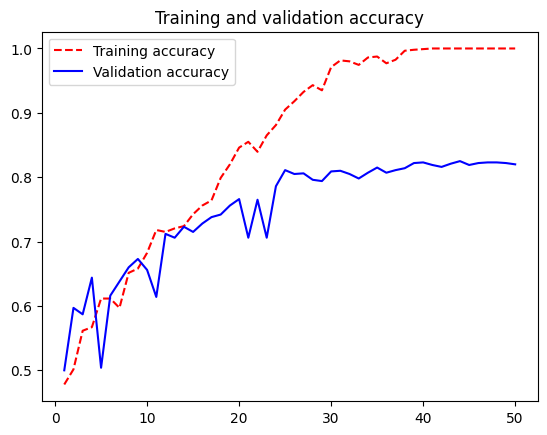

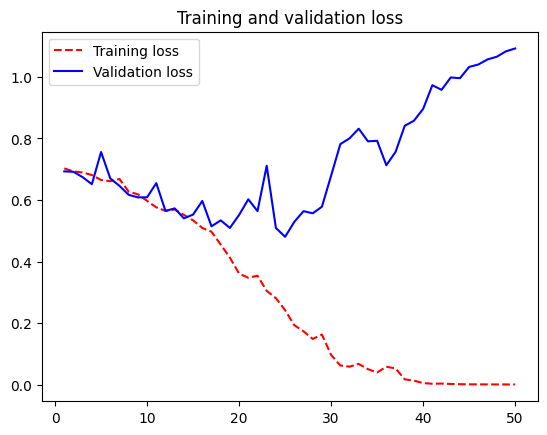

In [ ]:
import matplotlib.pyplot as plt

accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(accuracy) + 1)

plt.plot(epochs, accuracy, "r--", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.figure()

plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

# 과대적합: 훈련 정확도->100%, 검증 정확도 최고 80%
# 검증 손실은 더 이상 줄지 않음, 훈련 손실은 계속 감소

In [ ]:
test_model = keras.models.load_model("convnet_from_scratch.keras")   # 성능이 가장 좋은 모델 로드
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.8050 - loss: 0.4889
Test accuracy: 0.805


#### Using data augmentation

In [ ]:
# 과대적합은 학습할 샘플이 너무 적어 새로운 데이터에 일반화할 수 있는 모델을 훈련시킬 수 없기 때문에 발생
# 데이터 증강은 기존 훈련 샘플로부터 더 많은 훈련 데이터를 생성하는 방법
# 기존 이미지에 좌우 반전, 회전, 확대·축소 등의 변화

# 데이터 증강의 두 가지 방법
# 1) 모델의 시작 부분(모델 내부). 이 예제에서는 rescaling 층 직전에 추가 -> GPU에서 실행
# 2) 데이터 파이프라인 내부(모델 외부). 이 예제에서는 map() 호출을 통해 dataset에 적용 -> CPU에서 (병렬적으로) 실행
# 일반적으로 2)가 더 좋은 방법

data_augmentation_layers = [   # 적용할 이미지 변환을 저장
    layers.RandomFlip("horizontal"),   # 좌우 반전
    layers.RandomRotation(0.1),   # 무작위 회전 (360*0.1=36 -> +/- 36도 회전)
    layers.RandomZoom(0.2),   # 무작위 확대 축소 -> 이미지의 일부가 더 크게 보이거나 전체가 상대적으로 작게 보이도록 변형 (높이와 너비 방향에 최대 약 20% 수준의 무작위 줌 변화)
]

def data_augmentation(images, targets):   # 원본 이미지와 그 정답 label
    for layer in data_augmentation_layers:
        images = layer(images)   # 앞에서 정의한 이미지 변환 (좌우 반전, 회전, 확대 축소)
    return images, targets   # 변환된 이미지와 원래 정답을 함께 반환

augmented_train_dataset = train_dataset.map(   # 원본 학습 데이터셋의 각 배치 또는 요소에 증강 함수를 적용
    data_augmentation, num_parallel_calls=8   # 정의한 데이터 증강 함수를 CPU의 8개 병렬 스레드(num_parallel_calls=8)를 사용해 원본 훈련 데이터셋 전체에 빠르게 일괄 적용
)
augmented_train_dataset = augmented_train_dataset.prefetch(tf.data.AUTOTUNE)   # prefetch: cpu & gpu together
# 모델이 GPU에서 현재 배치로 학습하는 동안, CPU는 백그라운드에서 다음 배치의 데이터 증강 및 전처리를 미리 수행하여 준비
# CPU와 GPU의 대기 시간을 최소화하고 학습 속도를 극대화

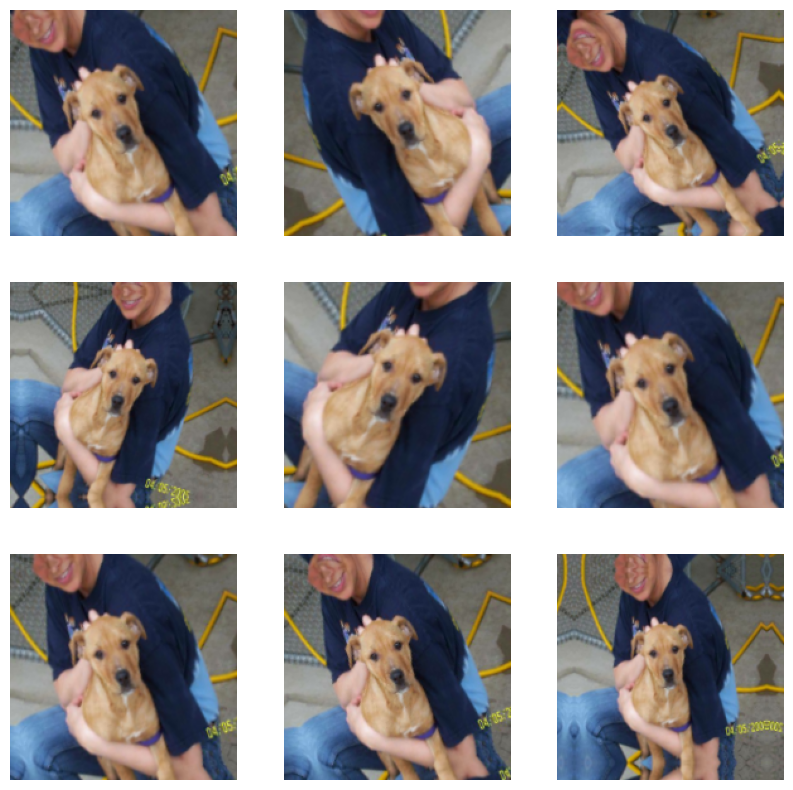

In [ ]:
plt.figure(figsize=(10, 10))
for image_batch, _ in train_dataset.take(1):   # 학습 이미지 데이터셋에서 한 개의 배치를 가져옴
    image = image_batch[0]   # 배치에서 이미지 한 장을 선택
    for i in range(9):   # 9개의 이미지 공간 만들기
        ax = plt.subplot(3, 3, i + 1)   # 그래프를 3행 3열로 만들고 현재 이미지를 표시할 위치 지정 (subplot의 위치 번호는 1부터 시작하기 때문에 i+1 사용)
        augmented_image, _ = data_augmentation(image, None)   # 앞에서 정의한 데이터 증강 함수를 호출
        augmented_image = keras.ops.convert_to_numpy(augmented_image)   # Matplotlib에서 이미지 데이터를 다루기 쉽게 텐서를 NumPy 배열로 변환
        plt.imshow(augmented_image.astype("uint8"))   # 이미지 값을 8비트 정수 형식으로 변환하여 그래프에 표시
        plt.axis("off")   # 좌표축과 눈금 숫자 숨기기

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))   # 180x180 크기의 RGB 채널(3)을 가진 이미지를 입력
x = layers.Rescaling(1.0 / 255)(inputs)   # uint8: 2^8=256 -> 0~255 사이인 픽셀 값의 범위를 0~1로 정규화
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)   # 2x2 영역에서 최댓값 선택
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)   # dropout: 학습하는 동안 25%의 뉴런을 무작위로 비활성화하여 모델이 특정 뉴런에 지나치게 의존하지 않도록 -> 과적합 방지
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss",
    )
]
history = model.fit(
    augmented_train_dataset,
    epochs=100,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 26s 645ms/step - accuracy: 0.4980 - loss: 0.6959 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 13s 376ms/step - accuracy: 0.5140 - loss: 0.6924 - val_accuracy: 0.5690 - val_loss: 0.6860
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 667ms/step - accuracy: 0.5625 - loss: 0.6832 - val_accuracy: 0.5400 - val_loss: 0.6848
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 602ms/step - accuracy: 0.5155 - loss: 0.6913 - val_accuracy: 0.5850 - val_loss: 0.6860
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 667ms/step - accuracy: 0.5835 - loss: 0.6757 - val_accuracy: 0.6040 - val_loss: 0.6530
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 13s 354ms/step - accuracy: 0.6235 - loss: 0.6468 - val_accuracy: 0.6510 - val_loss: 0.6227
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 349ms/step - accuracy: 0.6410 - loss: 0.6361 - val_accuracy: 0.6520 - val_loss: 0.6181
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 416ms/step - accuracy: 0.6455 - loss: 0.6195 - 

In [ ]:
test_model = keras.models.load_model(
    "convnet_from_scratch_with_augmentation.keras"
)
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")
# 데이터 증강 -> 테스트 정확도 상승

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.8510 - loss: 0.3739
Test accuracy: 0.851


Some questions

In [ ]:
# Change RandomRotation (0.1) to RandomRotation (0.3) in the data augmentation
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
]

def data_augmentation(images, targets):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images, targets

augmented_train_dataset = train_dataset.map(
    data_augmentation, num_parallel_calls=8
)
augmented_train_dataset = augmented_train_dataset.prefetch(tf.data.AUTOTUNE)

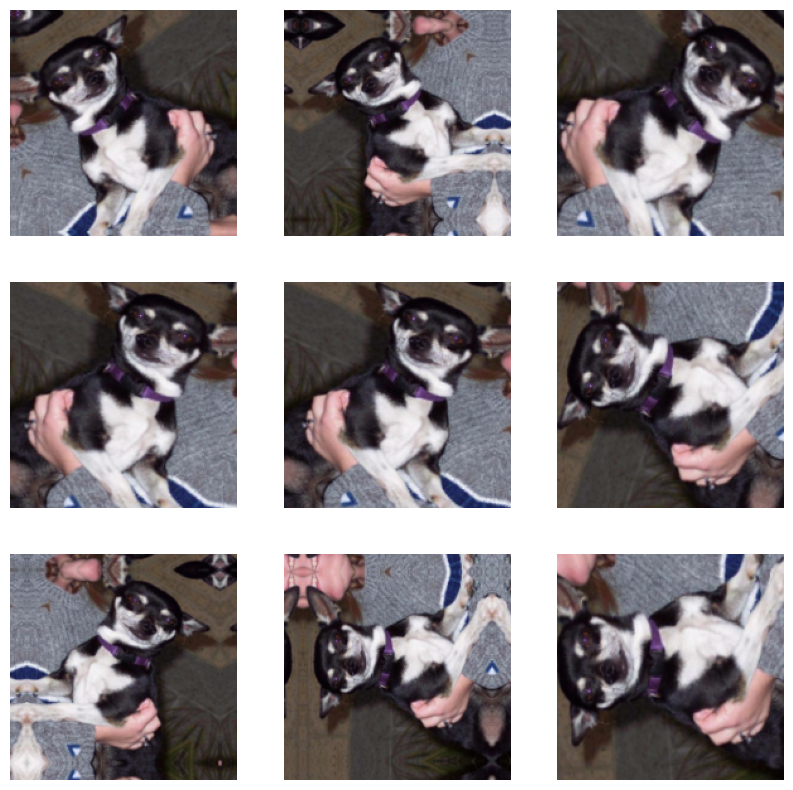

In [ ]:
# Visualize how the augmented images change.
plt.figure(figsize=(10, 10))
for image_batch, _ in train_dataset.take(1):
    image = image_batch[0]
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        augmented_image, _ = data_augmentation(image, None)
        augmented_image = keras.ops.convert_to_numpy(augmented_image)
        plt.imshow(augmented_image.astype("uint8"))
        plt.axis("off")

In [ ]:
# Try different augmentation methods and discuss about better realistic augmentation with teammates.
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.3),
    layers.RandomColorJitter(value_range=(0, 255)),
    layers.RandomZoom(0.2),
]

def data_augmentation(images, targets):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images, targets

augmented_train_dataset = train_dataset.map(
    data_augmentation, num_parallel_calls=8
)
augmented_train_dataset = augmented_train_dataset.prefetch(tf.data.AUTOTUNE)

### Using a pretrained model

#### Feature extraction with a pretrained model

In [ ]:
import keras_hub

conv_base = keras_hub.models.Backbone.from_preset("xception_41_imagenet")
# Backbone: 분류 헤드를 제외한 특성 추출 네트워크
# from_preset(): 모델의 설정과 가중치 내려받기

In [ ]:
preprocessor = keras_hub.layers.ImageConverter.from_preset(
    "xception_41_imagenet",
    image_size=(180, 180),
)
# keras_hub.layers.ImageConverter: 이미지 입력을 모델에 맞게 변환하는 레이어
# .from_preset(): 미리 정의된 설정(Preset)을 불러와 객체 생성

##### Fast feature extraction without data augmentation

In [ ]:
# 사전학습된 conv_base 모델을 사용하여 이미지 특성과 해당 레이블 추출하기
def get_features_and_labels(dataset):
    all_features = []   # all_features = []: 추출한 이미지 특징을 저장할 리스트
    all_labels = []   # all_labels = []: 각 이미지의 정답 레이블을 저장할 리스트
    for images, labels in dataset:   # images: 이미지 배치, labels: 각 이미지에 대응하는 정답
        preprocessed_images = preprocessor(images)   # 앞에서 만든 preprocessor를 사용해 이미지를 Xception 모델의 입력 형식에 맞게 변환
        features = conv_base.predict(preprocessed_images, verbose=0)   # 사전 학습된 CNN 특징 추출기(conv_base)입력 이미지에서 출력을 계산 (verbose=0: 진행 상태를 화면에 출력하지X)
        all_features.append(features)   # 추출한 특징과 레이블 저장
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)   # 리스트를 하나의 배열로 합치기

# 학습·검증·테스트 데이터를 특징 추출 함수에 전달
train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

In [ ]:
train_features.shape

(2000, 6, 6, 2048)

In [ ]:
# 밀집 연결 분류기를 정의하고 훈련하기
inputs = keras.Input(shape=(6, 6, 2048))
x = layers.GlobalAveragePooling2D()(inputs)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction.keras",
        save_best_only=True,
        monitor="val_loss",
    )
]
history = model.fit(
    train_features,
    train_labels,
    epochs=10,
    validation_data=(val_features, val_labels),
    callbacks=callbacks,
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.9685 - loss: 0.1032 - val_accuracy: 0.9850 - val_loss: 0.0537
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9900 - loss: 0.0342 - val_accuracy: 0.9810 - val_loss: 0.0554
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9945 - loss: 0.0169 - val_accuracy: 0.9820 - val_loss: 0.0561
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9990 - loss: 0.0077 - val_accuracy: 0.9840 - val_loss: 0.0583
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9995 - loss: 0.0029 - val_accuracy: 0.9850 - val_loss: 0.0564
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.9860 - val_loss: 0.0552
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 8.5803e-04 - val_accuracy: 0.9860 - val_loss: 0.0546
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 6.9765e-04 - val_accuracy: 0.9850 - 

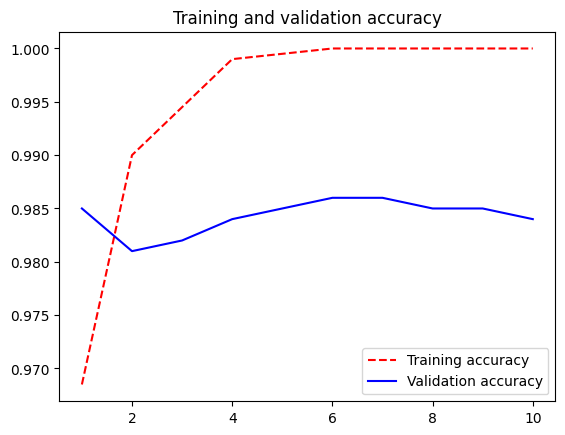

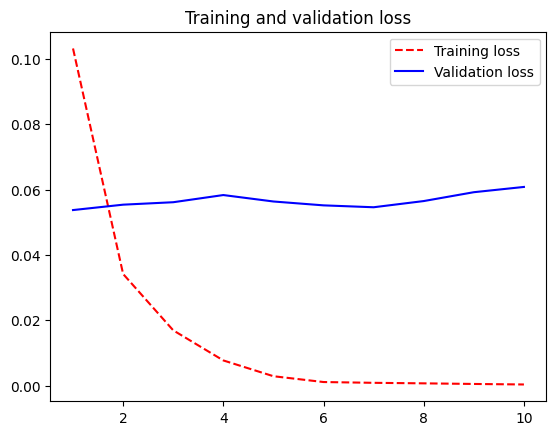

In [ ]:
import matplotlib.pyplot as plt

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(acc) + 1)
plt.plot(epochs, acc, "r--", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()


# dropout을 사용했음에도 데이터 증강을 하지 않아 훈련 시작하고 곧바로 과대적합

In [ ]:
test_model = keras.models.load_model("feature_extraction.keras")
test_loss, test_acc = test_model.evaluate(test_features, test_labels)
print(f"Test accuracy: {test_acc:.3f}")

# 사전 학습된 모델에서 특성과 레이블 추출 -> 이미지 분류기 학습
# 테스트 정확도 98%

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9825 - loss: 0.0607
Test accuracy: 0.983


##### Feature extraction together with data augmentation

In [ ]:
import keras_hub

conv_base = keras_hub.models.Backbone.from_preset(
    "xception_41_imagenet",
    trainable=False,   # 합성곱 백본을 동결 (훈련하는 동안 가중치가 업데이트되지 않도록)
)

In [ ]:
conv_base.trainable = True
len(conv_base.trainable_weights)   # 합성곱 백본을 동결하기 전에 훈련 가능한 가중치 개수

154

In [ ]:
conv_base.trainable = False   # freeze the trained conv base network
len(conv_base.trainable_weights)   # 합성곱 백본을 동결한 후 훈련 가능한 가중치 개수

0

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))
x = preprocessor(inputs)
x = conv_base(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256)(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)
# 추가한 2개의 dense층 가중치만 훈련
# 층마다 2개씩 (가중치 행렬과 편향 벡터) 총 4개의 텐서가 훈련

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ image_converter                 │ (None, 180, 180, 3)    │             0 │
│ (ImageConverter)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception_backbone               │ (None, 6, 6, 2048)     │    20,861,480 │
│ (XceptionBackbone)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,386,281 (81.58 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 20,861,480 (79.58 MB)

In [ ]:
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction_with_data_augmentation.keras",
        save_best_only=True,
        monitor="val_loss",
    )
]
history = model.fit(
    augmented_train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 30s 636ms/step - accuracy: 0.8650 - loss: 0.3937 - val_accuracy: 0.9860 - val_loss: 0.0526
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 450ms/step - accuracy: 0.9325 - loss: 0.1598 - val_accuracy: 0.9880 - val_loss: 0.0478
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 454ms/step - accuracy: 0.9250 - loss: 0.1901 - val_accuracy: 0.9880 - val_loss: 0.0401
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 710ms/step - accuracy: 0.9365 - loss: 0.1675 - val_accuracy: 0.9860 - val_loss: 0.0426
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 704ms/step - accuracy: 0.9390 - loss: 0.1718 - val_accuracy: 0.9760 - val_loss: 0.0710
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 677ms/step - accuracy: 0.9395 - loss: 0.1593 - val_accuracy: 0.9810 - val_loss: 0.0515
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 24s 706ms/step - accuracy: 0.9445 - loss: 0.1527 - val_accuracy: 0.9820 - val_loss: 0.0601
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 430ms/step - accuracy: 0.9470 - loss: 0.1456 - val_accu

In [ ]:
test_model = keras.models.load_model(
    "feature_extraction_with_data_augmentation.keras"
)
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")
# 테스트 정확도 98%

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_5', because it has 318 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 196ms/step - accuracy: 0.9835 - loss: 0.0535
Test accuracy: 0.984


Some questions

In [ ]:
# What does trainable=False mean?
# the model's weights will not be updated during training. In other words, the layer or model is frozen.

In [ ]:
# Briefly explain why we use a pretrained model.
# Pretrained model을 사용하면 이미 학습된 지식을 활용해 더 빠르고 효율적으로 딥러닝 모델을 만들 수 있다.
# 학습 시간 단축, 적은 데이터로도 좋은 성능, 높은 성능을 높기 쉬움, 계산자원과 비용 절약

#### Fine-tuning a pretrained model

In [ ]:
# skip

In [ ]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False
# 사전 학습된 모델에서 최상위 4개 층만 학습 가능

In [ ]:
model.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss",
    )
]
history = model.fit(
    augmented_train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

In [ ]:
model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")